In [32]:
import torch
import torch.optim as optim
import numpy as np
import pandas as pd

from utils.phase import Phase
from utils.loss_function_parameters import LossParameters
from utils.model_utils import criterion_to_str, get_predictor
from utils.model_utils import compare_kendal_tau_models, compare_mean_mae_models, plot_loss_modes_comparison
from utils.model_utils import collect_grid_search_results, plot_grid_search_heatmap, plot_mean_results_heatmap, plot_mean_results_heatmap_3_params
from data_augmentation.monte_carlo_loader import MonteCarloLoader
from model.architecture.dense_monte_carlo import DenseMonteCarloNet
from model.model_loader import ModelLoader
from analytic_methods.EVM_method import EVM
from visualization.results.metrics_visualizator import MetricsVisualizator
from visualization.data.weights_visualizator import WeightsVisualizator
from metrics.evaluator import Evaluator

viz = MetricsVisualizator()
evaluator = Evaluator()
loader = MonteCarloLoader()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device used: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

LAYERS = 4
EXPANSION_FACTOR = 12
DROPOUT_RATE = 0.2
NEGATIVE_SLOPE = 0.5
LEARNING_RATE = 0.0001
BATCH_SIZE = 512
BATCH_NORM = False
STRATA = ['low_inconsistency', 'moderate_inconsistency', 'high_inconsistency']

Device used: cpu


## Compare 5 criteria models

### Choosing loss function parts weights 

History and model: cop30b_fit45_stab25k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop45m_fit40_stab15k_margin10_p2 loaded from models\dense_optimized\criteria5
History and model: cop50m_fit45_stab5k_margin5_p1 loaded from models\dense_optimized\criteria5
History and model: cop50m_fit45_stab5k_margin5_p2_entr1 loaded from models\dense_optimized\criteria5
History and model: cop50m_fit45_stab5k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop50m_fit45_stab5r_margin5_p2_q200_entr1 loaded from models\dense_optimized\criteria5


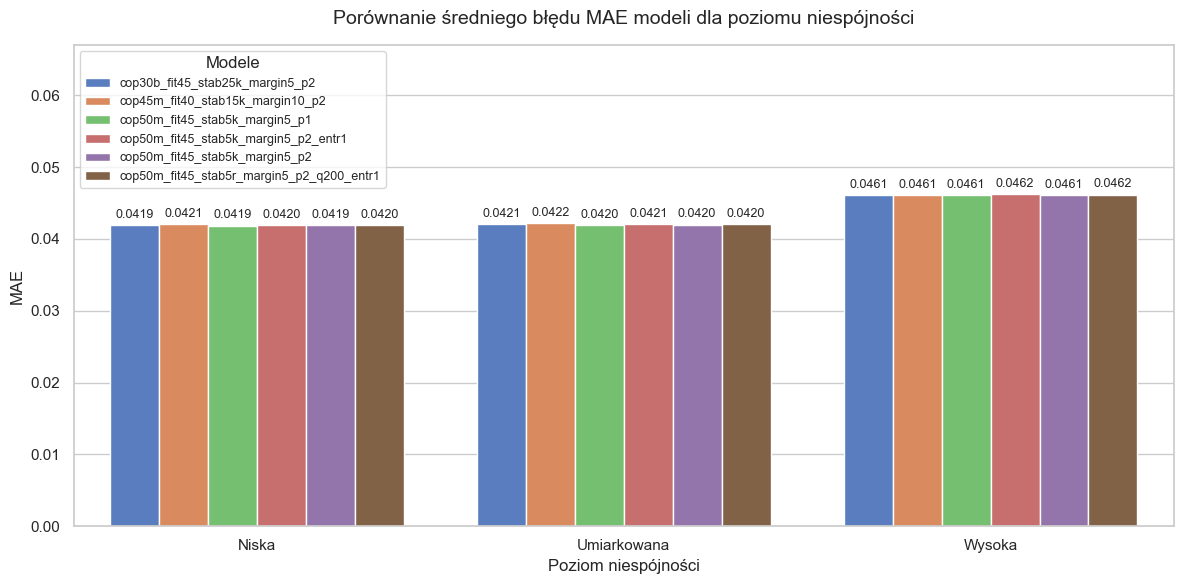

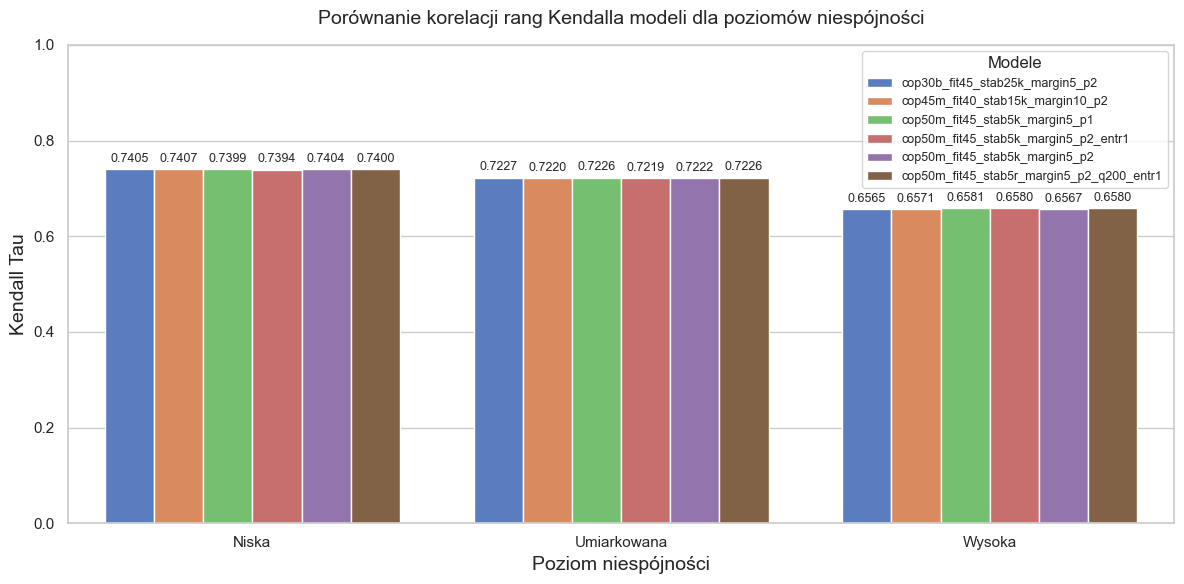

In [33]:
CRITERIA_NUM = 5

    # COP, FIT, STAB, P (FIT_MODE), MARGIN, NORMALIZE, COP_MODE, STAB_MODE, ENTROPY_THRESHOLD, Q
PARAMETERS = [
    [0.3, 0.45, 0.25, 2, 0.05, False, "bradley", "kullback", None, 2, "dense_optimized"],
    [0.45, 0.4, 0.15, 2, 0.1, False, "margin", "kullback", None, 2, "dense_optimized"],
    # [0.4, 0.55, 0.05, 2, 0.05, False, "bradley", "kullback", None, 2, "dense_optimized"],
    [0.5, 0.45, 0.05, 1, 0.05, False, "margin", "kullback", None, 2, "dense_optimized"],
    [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "kullback", 0.01, 2, "dense_optimized"],
    [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "kullback", None, 2, "dense_optimized"],
    [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "renyi", 0.01, 2, "dense_optimized"]
]

true_weights = {}
predicted_priority_weights = {stratum: [] for stratum in STRATA}
model_names = []

for param in PARAMETERS:
    trainer, criterion_str = get_predictor(
        device, param[0], param[1], param[2], param[4], param[3], param[6], param[7], param[5],
        param[8], param[9], LEARNING_RATE, CRITERIA_NUM, model_type=param[10]
    )
    model_names.append(criterion_str)

    for stratum in STRATA:
        test_mats, test_wts = loader.load_stratum(
            phase=Phase.TEST,
            num_criteria=CRITERIA_NUM,
            stratum=stratum,
            max_count=None
        )
        true_weights[stratum] = test_wts
        preds = trainer.predict_batch(test_mats)
        predicted_priority_weights[stratum].append(preds)

df_results_mae = compare_mean_mae_models(true_weights, predicted_priority_weights, model_names, legend_title="Modele")
df_results_tau = compare_kendal_tau_models(true_weights, predicted_priority_weights, model_names, legend_title="Modele")

### Loss function weights on heatmap

In [34]:
CRITERIA_NUM = 5

    # COP, FIT, STAB, P (FIT_MODE), MARGIN, NORMALIZE, COP_MODE, STAB_MODE, ENTROPY_THRESHOLD, Q
PARAMETERS = [
    [0.5, 0.45, 0.05, 1, 0.05, False, "margin", "kullback", None, 2],
    [0.5, 0.45, 0.05, 1, 0.05, False, "margin", "kullback", None, 2],
    [0.5, 0.45, 0.05, 2, 0.05, False, "margin", "kullback", None, 2],
    # [0.7, 0.25, 0.05, 1, 0.05, False, "margin", "renyi", None, 2],
    [0.45, 0.40, 0.15, 1, 0.05, False, "margin", "kullback", None, 2],
    [0.45, 0.40, 0.15, 1, 0.05, False, "margin", "kullback", None, 2],
    # [0.7, 0.25, 0.05, 2, 0.05, False, "margin", "renyi", None, 2],
    [0.25, 0.7, 0.05, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.25, 0.7, 0.05, 2, 0.05, False, "bradley", "kullback", None, 2],
    [0.15, 0.8, 0.05, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.5, 0.5, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0, 0.95, 0.05, 2, 0.05, False, "margin", "renyi", None, 2],
    [0.55, 0.4, 0.05, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.6, 0.35, 0.05, 2, 0.05, False, "bradley", "kullback", None, 2],
    [0.5, 0.40, 0.10, 2, 0.05, False, "margin", "renyi", None, 2],
    # [0.65, 0.30, 0.05, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.40, 0.5, 0.10, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.35, 0.60, 0.05, 2, 0.05, False, "bradley", "kullback", None, 2],
    [0.3, 0.65, 0.05, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.4, 0.55, 0.05, 2, 0.05, False, "bradley", "renyi", None, 2],
    [0.4, 0.4, 0.20, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.5, 0.35, 0.15, 2, 0.05, False, "bradley", "kullback", None, 2],
    [0.5, 0.30, 0.20, 2, 0.05, False, "margin", "kullback", None, 2],
    # [0.6, 0.20, 0.20, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.35, 0.5, 0.15, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.35, 0.40, 0.25, 2, 0.05, False, "bradley", "renyi", None, 2],
    [0.2, 0.60, 0.20, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.50, 0.45, 0.05, 2, 0.05, False, "margin", "kullback", 0.01, 2],
    [0.50, 0.45, 0.05, 2, 0.05, False, "margin", "renyi", 0.01, 2]
]

PARAMETERS = [
    [0.5, 0.5, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.6, 0.4, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.4, 0.6, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.3, 0.7, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.7, 0.3, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.2, 0.8, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.8, 0.2, 0, 2, 0.05, False, "margin", "kullback", None, 2],

    [0.5, 0.4, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.6, 0.3, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.4, 0.5, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.3, 0.6, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.7, 0.2, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.2, 0.7, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],


    [0.3, 0.5, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.4, 0.4, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.3, 0.5, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.2, 0.6, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.6, 0.2, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.5, 0.3, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],

    [0.3, 0.4, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.4, 0.3, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.2, 0.5, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.1, 0.6, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.5, 0.2, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.6, 0.1, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],

    [0.2, 0.4, 0.4, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.3, 0.3, 0.4, 2, 0.05, False, "margin", "kullback", None, 2]

]

MODE_PARAMETERS = [
    [0.2, 0.5, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],

    [0.2, 0.5, 0.3, 2, 0.05, False, "bradley", "kullback", None, 2],
    [0.2, 0.5, 0.3, 1, 0.05, False, "margin", "kullback", None, 2],
    [0.2, 0.5, 0.3, 2, 0.05, False, "margin", "renyi", None, 2],

    [0.2, 0.5, 0.3, 1, 0.05, False, "bradley", "kullback", None, 2],
    [0.2, 0.5, 0.3, 2, 0.05, False, "bradley", "renyi", None, 2],
    [0.2, 0.5, 0.3, 1, 0.05, False, "bradley", "renyi", None, 2],

    [0.2, 0.5, 0.3, 1, 0.05, False, "margin", "renyi", None, 2]
]

OTHER_PARAMETERS = [

]

ZERO_PARAMETERS = [
    [0, 0.9, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0, 0.6, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0, 0.7, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.9, 0, 0.1, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.8, 0, 0.2, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.7, 0, 0.3, 2, 0.05, False, "margin", "kullback", None, 2],

    [0.5, 0.5, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.6, 0.4, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.4, 0.6, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.3, 0.7, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.7, 0.3, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.2, 0.8, 0, 2, 0.05, False, "margin", "kullback", None, 2],
    [0.8, 0.2, 0, 2, 0.05, False, "margin", "kullback", None, 2]
]

test_matrices = {}
true_weights = {}

for stratum in STRATA:
    test_mats, test_wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=None
    )
    test_matrices[stratum] = test_mats
    true_weights[stratum] = test_wts

predicted_priority_weights = {stratum: [] for stratum in STRATA}
model_names = []
model_loader = ModelLoader()

for param in PARAMETERS:
    trainer, criterion_str = get_predictor(
        device, param[0], param[1], param[2], param[4], param[3], param[6], param[7], param[5], 
        param[8], param[9], LEARNING_RATE, CRITERIA_NUM, model_type="dense_optimized"
    )

    model_names.append(criterion_str)

    for stratum in STRATA:
        preds = trainer.predict_batch(test_matrices[stratum])
        predicted_priority_weights[stratum].append(preds)

grid_results_df = collect_grid_search_results(
    evaluator,
    true_weights,
    PARAMETERS,
    predicted_priority_weights,
    model_names
)

History and model: cop50m_fit50_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop60m_fit40_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop40m_fit60_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop30m_fit70_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop70m_fit30_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop20m_fit80_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop80m_fit20_stab0k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop50m_fit40_stab10k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop60m_fit30_stab10k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop40m_fit50_stab10k_margin5_p2 loaded from models\dense_optimized\criteria5
History and model: cop30m_fit60_stab10k_margin5

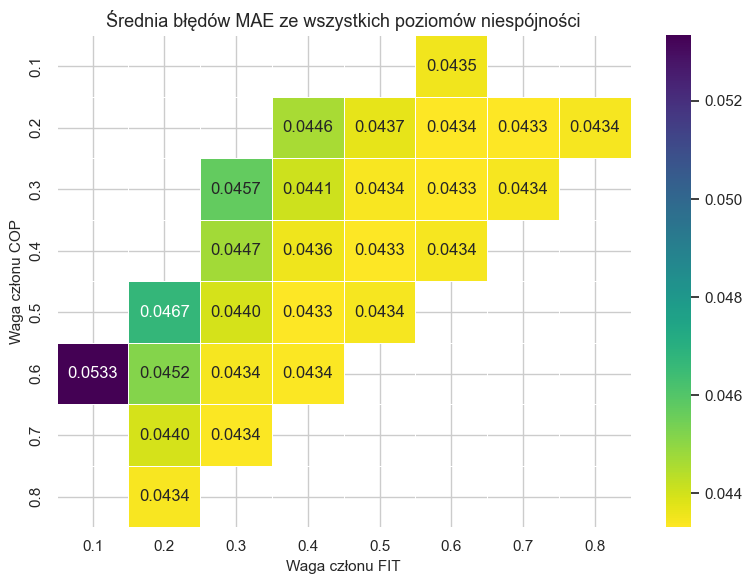

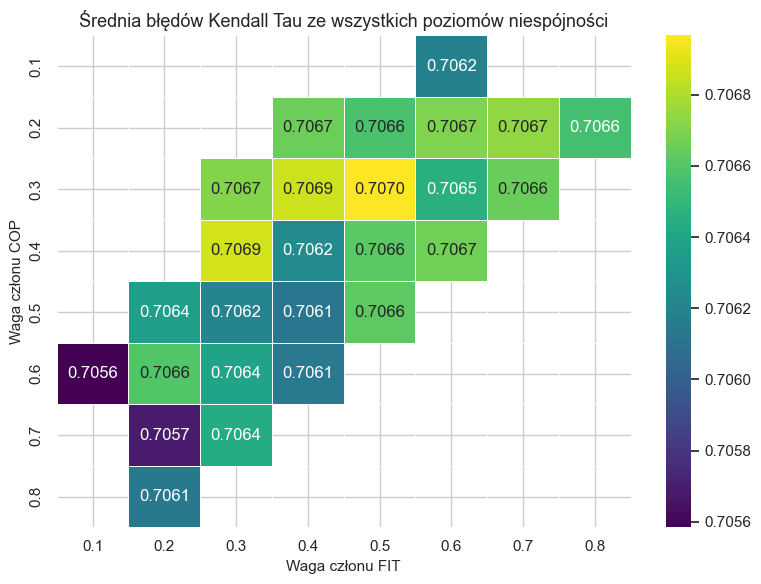

In [35]:
plot_mean_results_heatmap(grid_results_df, 'mae', LossParameters.COP_WEIGHT, LossParameters.FIT_WEIGHT)
plot_mean_results_heatmap(grid_results_df, 'kendall_tau', LossParameters.COP_WEIGHT, LossParameters.FIT_WEIGHT)

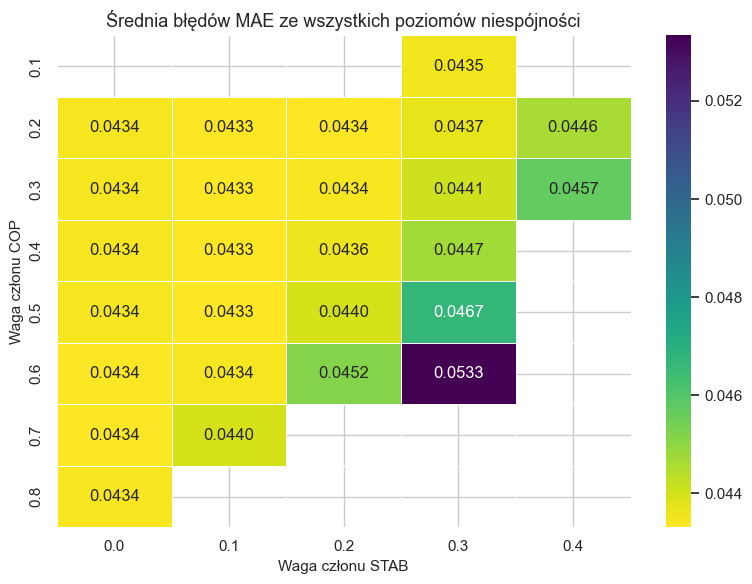

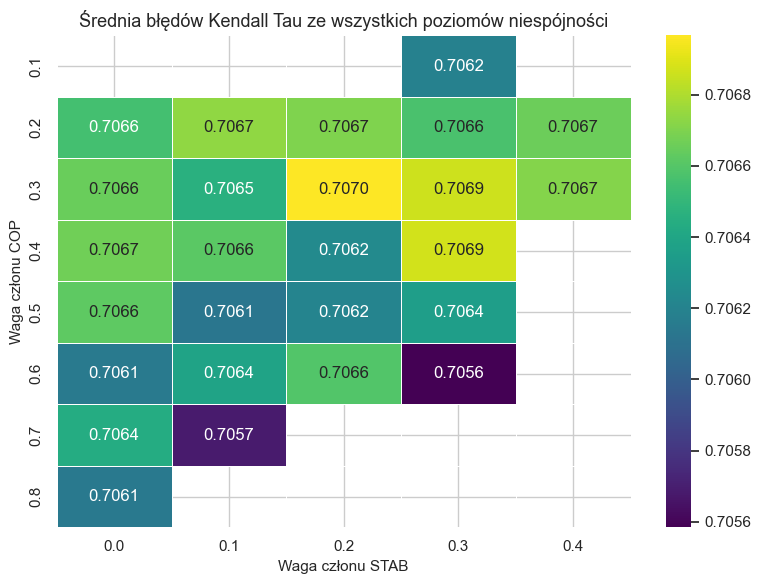

In [36]:
plot_mean_results_heatmap(grid_results_df, 'mae', LossParameters.COP_WEIGHT, LossParameters.STAB_WEIGHT)
plot_mean_results_heatmap(grid_results_df, 'kendall_tau', LossParameters.COP_WEIGHT, LossParameters.STAB_WEIGHT)

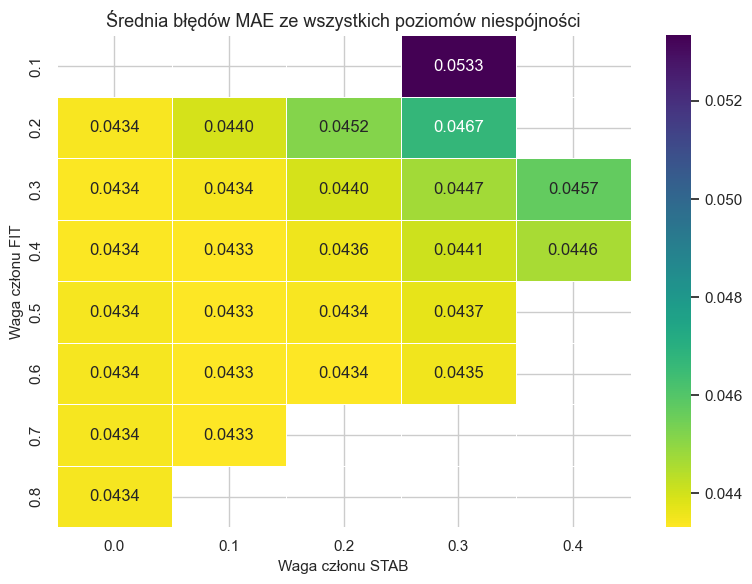

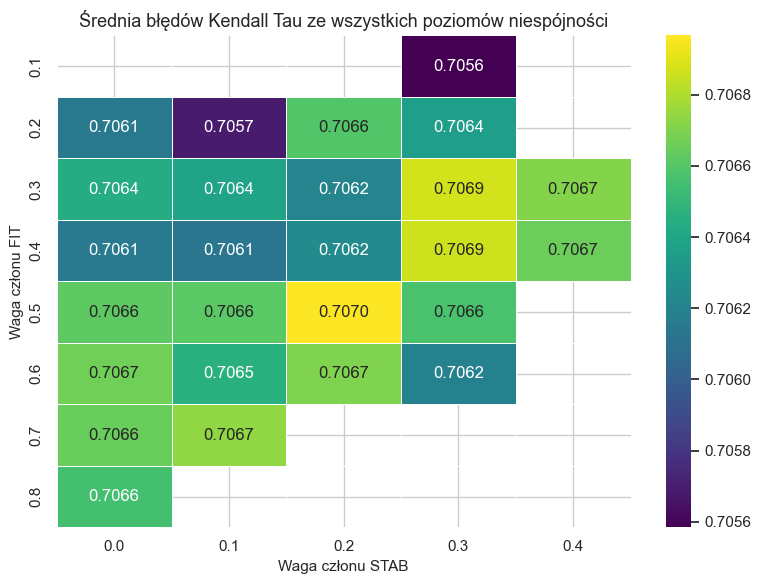

In [37]:
plot_mean_results_heatmap(grid_results_df, 'mae', LossParameters.FIT_WEIGHT, LossParameters.STAB_WEIGHT)
plot_mean_results_heatmap(grid_results_df, 'kendall_tau', LossParameters.FIT_WEIGHT, LossParameters.STAB_WEIGHT)

### Investigating the impact of different loss function parts

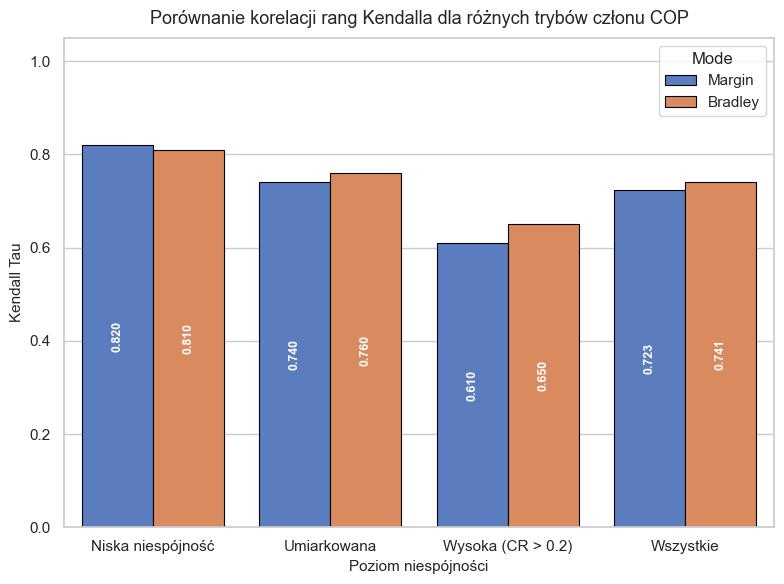

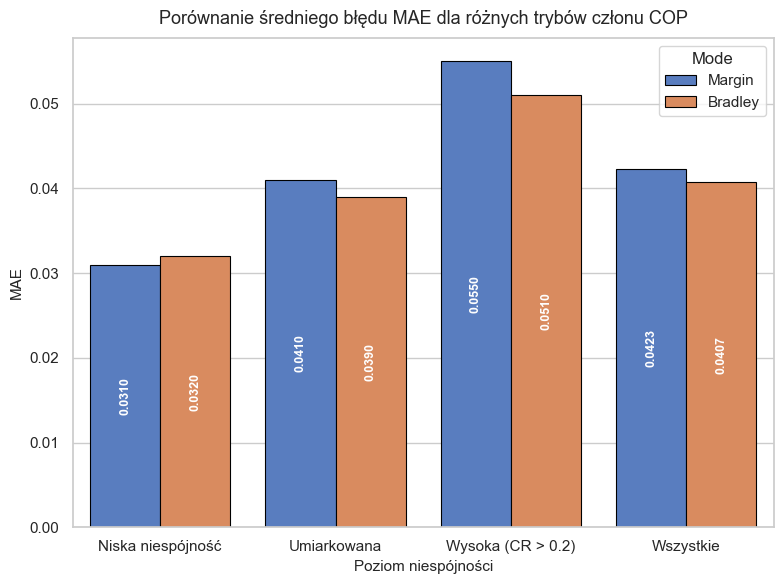

In [38]:
data = []
strata_names = ["Niska niespójność", "Umiarkowana", "Wysoka (CR > 0.2)", "Wszystkie"]

for mode_name, tau_vals, mae_vals in [("Margin", [0.82, 0.74, 0.61, 0.723], [0.031, 0.041, 0.055, 0.0423]),
                                      ("Bradley", [0.81, 0.76, 0.65, 0.741], [0.032, 0.039, 0.051, 0.0407])]:
    for stratum, tau, mae in zip(strata_names, tau_vals, mae_vals):
        data.append({"Inconsistency": stratum, "Mode": mode_name, "Kendall_Tau": tau, "MAE": mae})

df_plot = pd.DataFrame(data)
plot_loss_modes_comparison(df_plot, mode_col="Mode", title_suffix="COP")

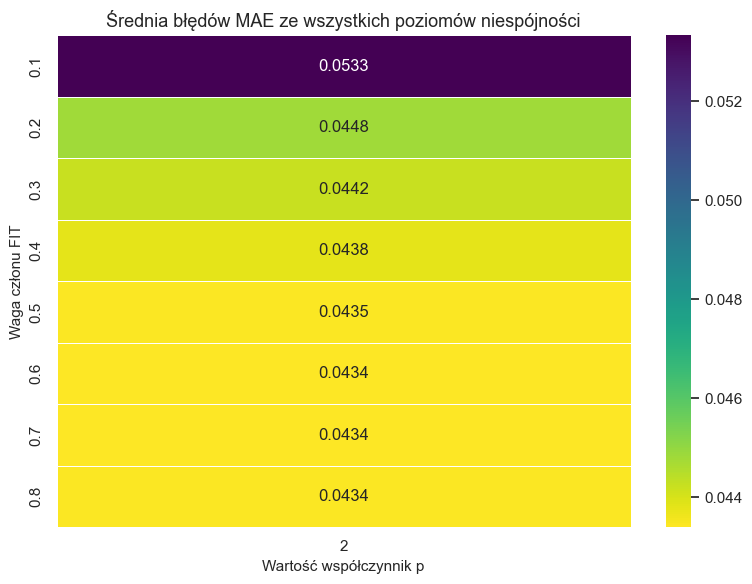

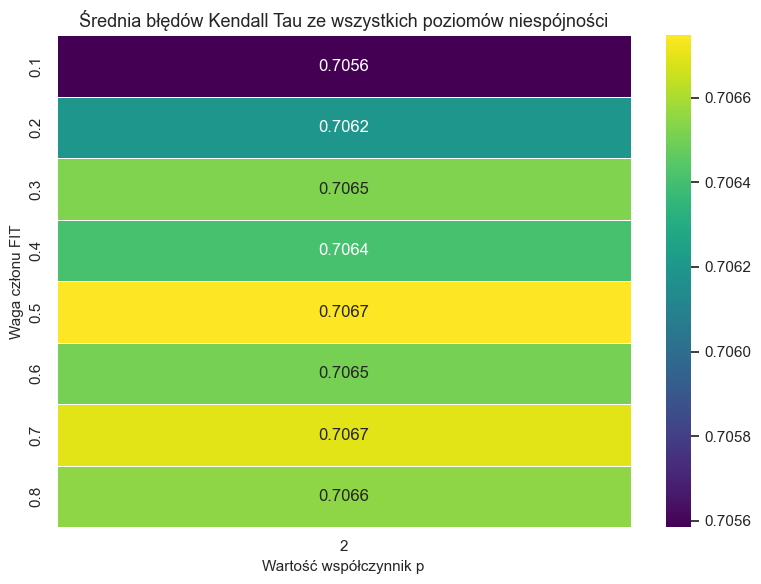

In [39]:
plot_mean_results_heatmap(grid_results_df, 'mae', LossParameters.FIT_WEIGHT, LossParameters.P)
plot_mean_results_heatmap(grid_results_df, 'kendall_tau', LossParameters.FIT_WEIGHT, LossParameters.P)

### Investigating the impact of other parameters

### Comparing with analytical methods

History and model: cop35m_fit50_stab15k_margin5_p2 loaded from models\dense_optimized\criteria5


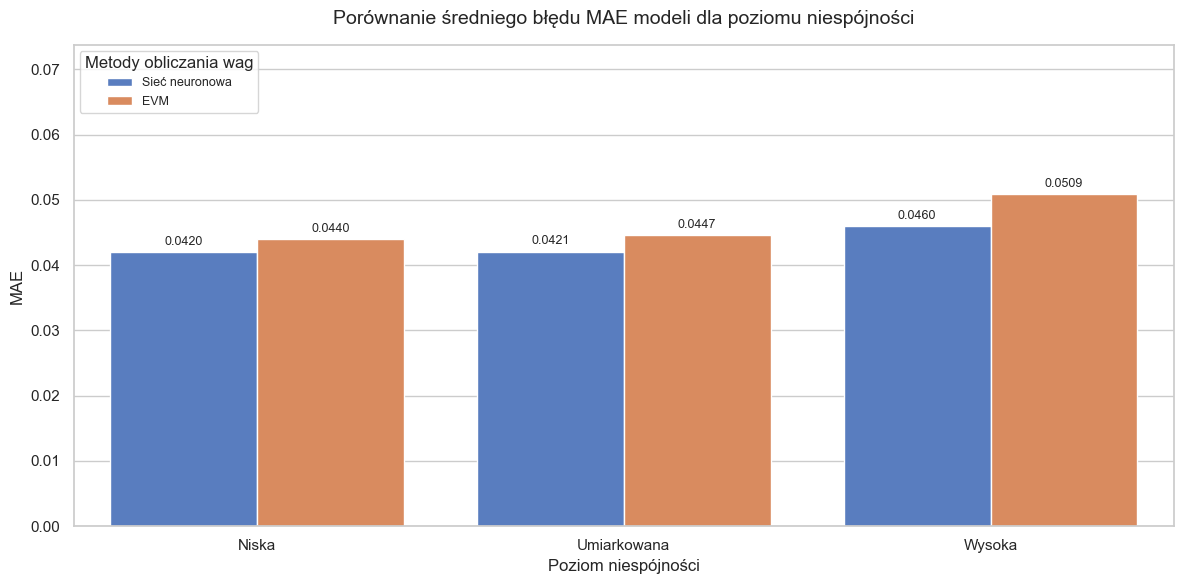

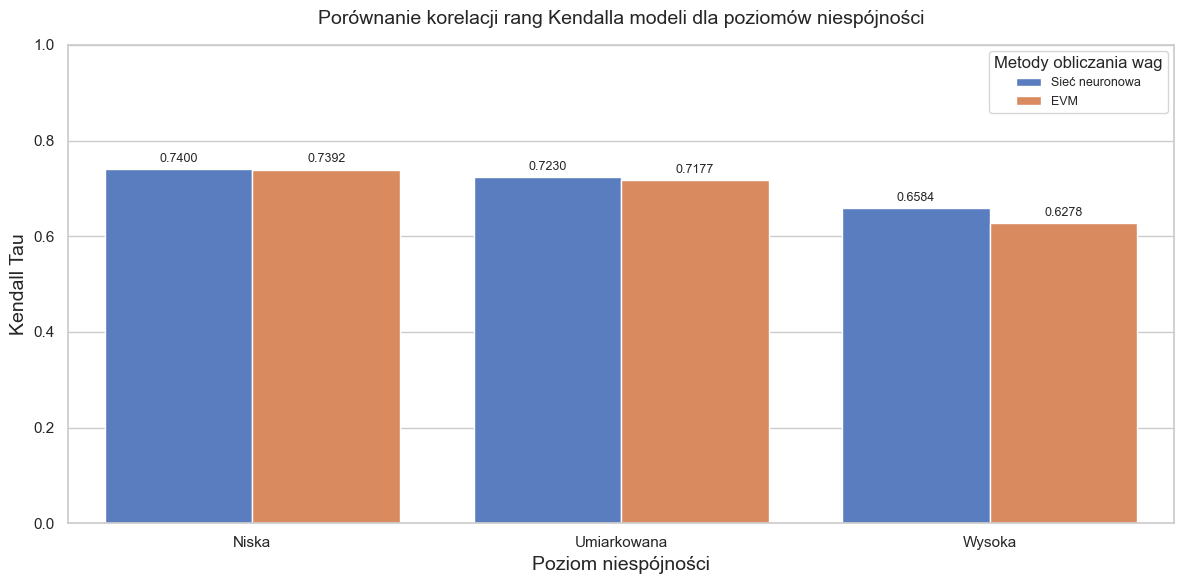

In [40]:
CRITERIA_NUM = 5

NORMALIZE_INITIAL_LOSS = False
COP = 0.35
FIT = 0.50
STAB = 0.15
P = 2 # FIT_MODE
MARGIN = 0.05
EPOCHS = 500
COP_MODE = "margin" 
STAB_MODE = "kullback"
ENTROPY_THRESHOLD = None
Q = 2

test_matrices = {}
true_weights = {}
evm_solver = EVM()
# another method can be added
evm_priority_weights = {}

for stratum in STRATA:
    test_mats, test_wts = loader.load_stratum(
        phase=Phase.TEST,
        num_criteria=CRITERIA_NUM,
        stratum=stratum,
        max_count=None
    )
    test_matrices[stratum] = test_mats
    true_weights[stratum] = test_wts
    evm_pw, _ = evm_solver.compute_batch(test_mats)
    evm_priority_weights[stratum] = evm_pw

predicted_priority_weights = {stratum: [] for stratum in STRATA}
model_names = []

trainer, criterion_str = get_predictor(
    device, COP, FIT, STAB, MARGIN, P, COP_MODE, STAB_MODE, NORMALIZE_INITIAL_LOSS,
    ENTROPY_THRESHOLD, Q, LEARNING_RATE, CRITERIA_NUM, model_type="dense_optimized"
)

model_names.append("Sieć neuronowa")

for stratum in STRATA:
    preds = trainer.predict_batch(test_matrices[stratum])
    predicted_priority_weights[stratum].append(preds)

model_names.append("EVM")
for stratum in STRATA:
    predicted_priority_weights[stratum].append(evm_priority_weights[stratum])

df_results_mae = compare_mean_mae_models(true_weights, predicted_priority_weights, model_names)
df_results_tau = compare_kendal_tau_models(true_weights, predicted_priority_weights, model_names)

## Training process

In [41]:
CRITERIA_NUM = 5

NORMALIZE_INITIAL_LOSS = False
COP = 0.55
FIT = 0.40
STAB = 0.05
P = 2 # FIT_MODE
MARGIN = 0.05
EPOCHS = 500
COP_MODE = "margin" 
STAB_MODE = "kullback"
ENTROPY_THRESHOLD = None
Q = 2

criterion_str = criterion_to_str(COP, FIT, STAB, MARGIN, P, COP_MODE, STAB_MODE, NORMALIZE_INITIAL_LOSS, ENTROPY_THRESHOLD, Q,)
model_loader = ModelLoader()
empty_model = DenseMonteCarloNet(n_criteria=CRITERIA_NUM)
model, history = model_loader.load_dense_MC(empty_model, CRITERIA_NUM, criterion_str)

History and model: cop55m_fit40_stab5k_margin5_p2 loaded from models\dense_monte_carlo\criteria5


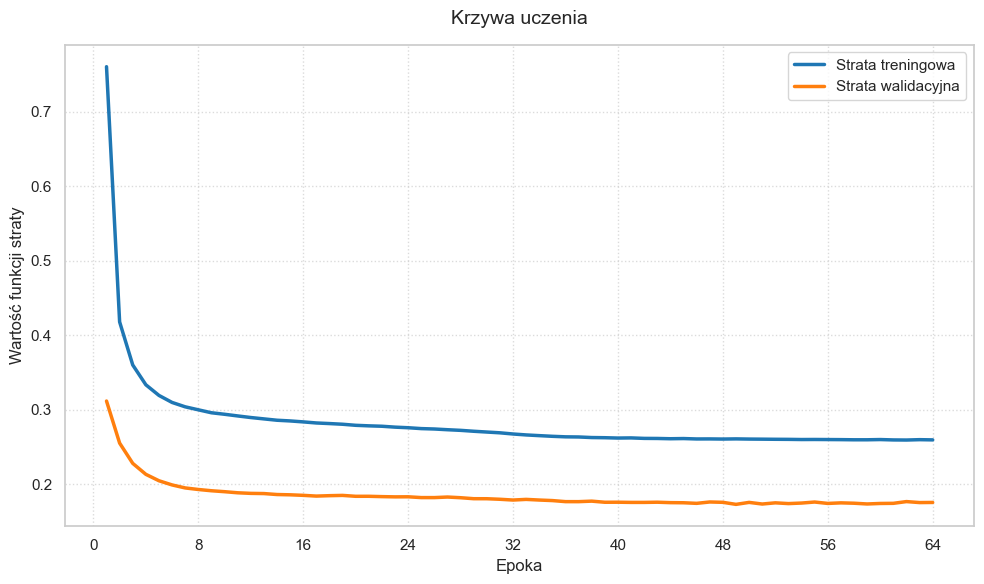

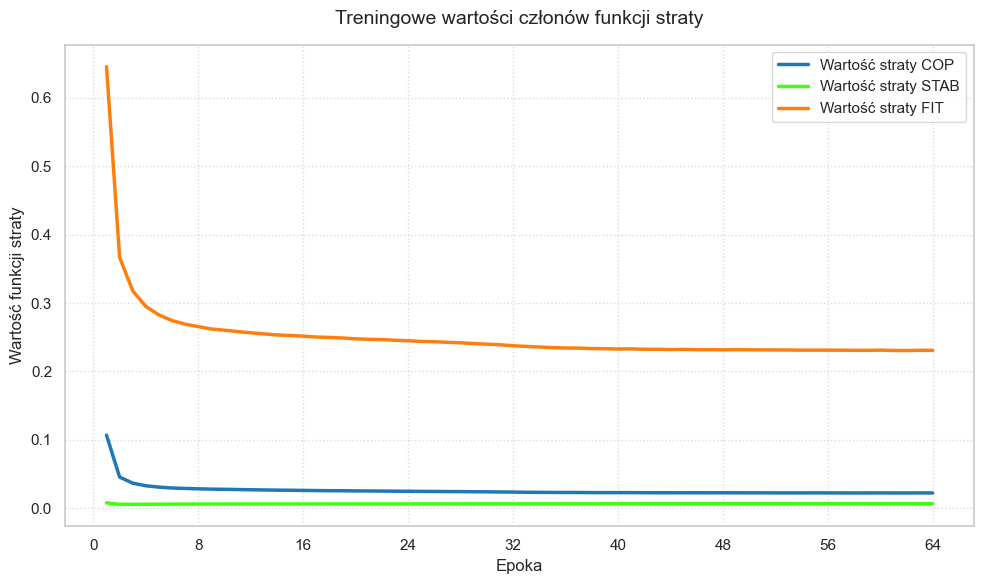

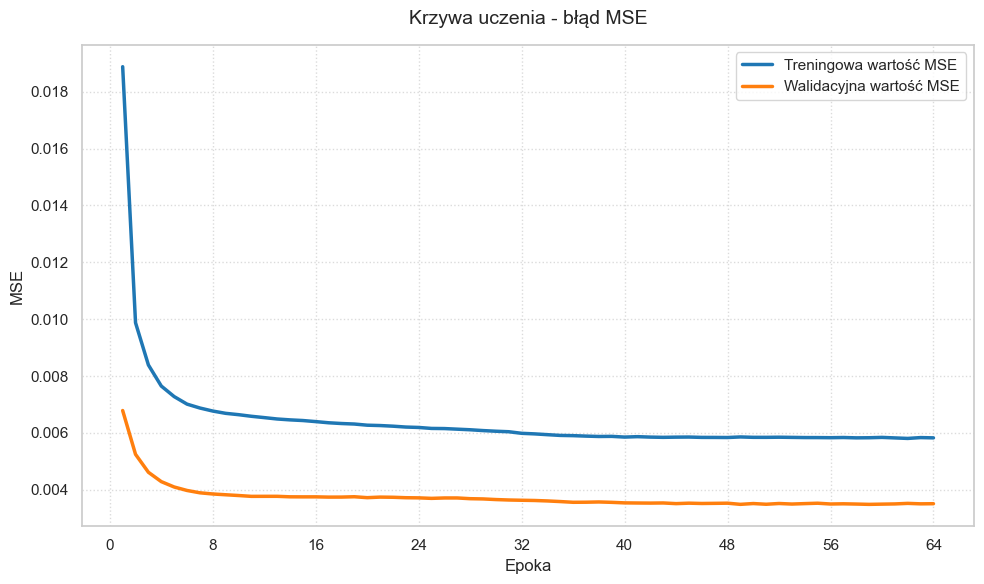

In [42]:
viz.display_loss(history)
viz.display_part_losses(history)
viz.display_learning_metric(history, 'mse')

## Comparing criterias

In [43]:
CRITERIA_NUMS = [3, 4, 5, 6, 7, 8, 9]
STRATA_POL = ['Niska niespójność', "Umiarkowana niespójność", "Wysoka niespójność"]

NORMALIZE_INITIAL_LOSS = False
COP = 0.35
FIT = 0.50
STAB = 0.15
P = 2 # FIT_MODE
MARGIN = 0.05
EPOCHS = 500
COP_MODE = "margin" 
STAB_MODE = "kullback"
ENTROPY_THRESHOLD = None
Q = 2
results = []

for criteria_num in CRITERIA_NUMS:
    trainer, criterion_str = get_predictor(
        device, COP, FIT, STAB, MARGIN, P, COP_MODE, STAB_MODE, NORMALIZE_INITIAL_LOSS, 
        ENTROPY_THRESHOLD, Q, LEARNING_RATE, criteria_num, model_type="dense_optimized"
    )

    for stratum, stratum_pol in zip(STRATA, STRATA_POL):
        test_mats, test_wts = loader.load_stratum(
            phase=Phase.TEST,
            num_criteria=criteria_num,
            stratum=stratum,
            max_count=None
        )
        pred_weights_n = trainer.predict_batch(test_mats)
        mae, tau, top1, spearman = evaluator.evaluate_batch(test_wts, pred_weights_n)
        results.append({
            "criteria": criteria_num,
            "stratum": stratum_pol,
            "mae": float(np.mean(mae)),
            "kendall_tau": float(np.mean(tau)),
            "top1": float(np.mean(top1)),
            "spearman": float(np.mean(spearman))
        })

df = pd.DataFrame(results)

FileNotFoundError: There are no files in models\dense_optimized\criteria3 for cop35m_fit50_stab15k_margin5_p2

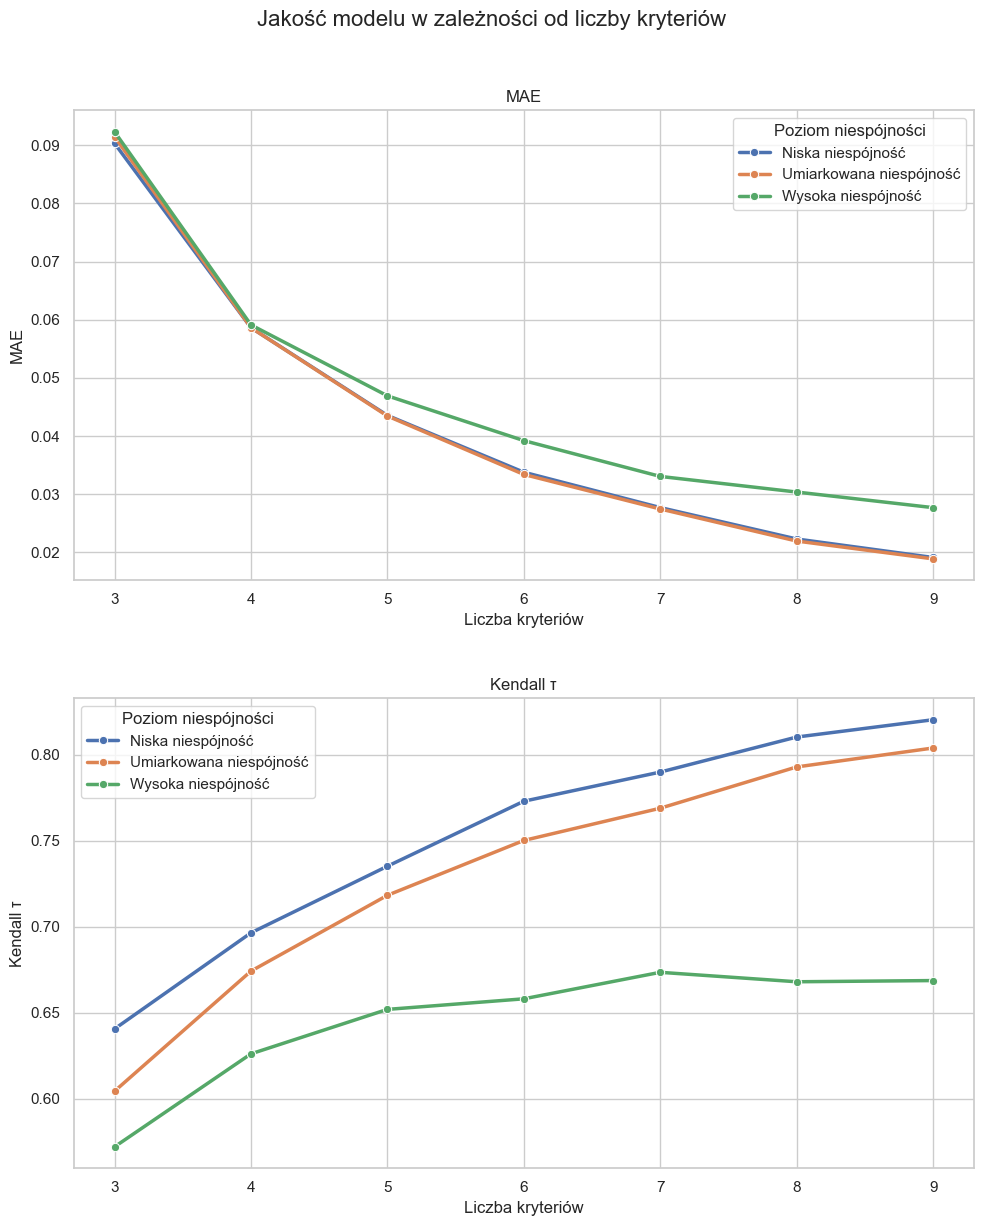

In [ ]:
viz.display_criteria_comparison(df, ['mae', 'kendall_tau'])